In [1]:
import polars as pl

RAW = "../data/raw"

tx = pl.read_csv(
    f"{RAW}/transactions_train.csv",
    schema_overrides={"article_id": pl.Utf8},
    try_parse_dates=True,
)
print(tx.shape) 
print(tx.schema)
print(f"Memory: {tx.estimated_size('gb'):.2f} GB")
tx.head()

(31788324, 5)
Schema([('t_dat', Date), ('customer_id', String), ('article_id', String), ('price', Float64), ('sales_channel_id', Int64)])
Memory: 2.78 GB


t_dat,customer_id,article_id,price,sales_channel_id
date,str,str,f64,i64
2018-09-20,"""000058a12d5b43e67d225668fa1f8d…","""0663713001""",0.050831,2
2018-09-20,"""000058a12d5b43e67d225668fa1f8d…","""0541518023""",0.030492,2
2018-09-20,"""00007d2de826758b65a93dd24ce629…","""0505221004""",0.015237,2
2018-09-20,"""00007d2de826758b65a93dd24ce629…","""0685687003""",0.016932,2
2018-09-20,"""00007d2de826758b65a93dd24ce629…","""0685687004""",0.016932,2


In [2]:
print("First date:", tx["t_dat"].min())
print("Last date: ", tx["t_dat"].max())
print("Customers who bought something:", tx["customer_id"].n_unique())
print("Different products bought:", tx["article_id"].n_unique())

First date: 2018-09-20
Last date:  2020-09-22
Customers who bought something: 1362281
Different products bought: 104547


In [ ]:
per_customer = tx.group_by("customer_id").len()
print(per_customer["len"].describe())

for n in [1, 5, 10]:
    share = (per_customer["len"] <= n).mean()
    print(f"Customers w ith <= {n} purchases: {share:.1%}")

shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 1.362281e6 │
│ null_count ┆ 0.0        │
│ mean       ┆ 23.334631  │
│ std        ┆ 39.242253  │
│ min        ┆ 1.0        │
│ 25%        ┆ 3.0        │
│ 50%        ┆ 9.0        │
│ 75%        ┆ 27.0       │
│ max        ┆ 1895.0     │
└────────────┴────────────┘
Customers with <= 1 purchases: 9.7%
Customers with <= 5 purchases: 36.8%
Customers with <= 10 purchases: 52.9%


In [4]:
top = tx.group_by("article_id").len().sort("len", descending=True)
total = tx.height

for k in [10, 100, 1000, 10000]:
    share = top["len"].head(k).sum() / total
    print(f"Top {k:>5} products = {share:.1%} of all purchases")

Top    10 products = 0.9% of all purchases
Top   100 products = 4.6% of all purchases
Top  1000 products = 18.2% of all purchases
Top 10000 products = 59.6% of all purchases


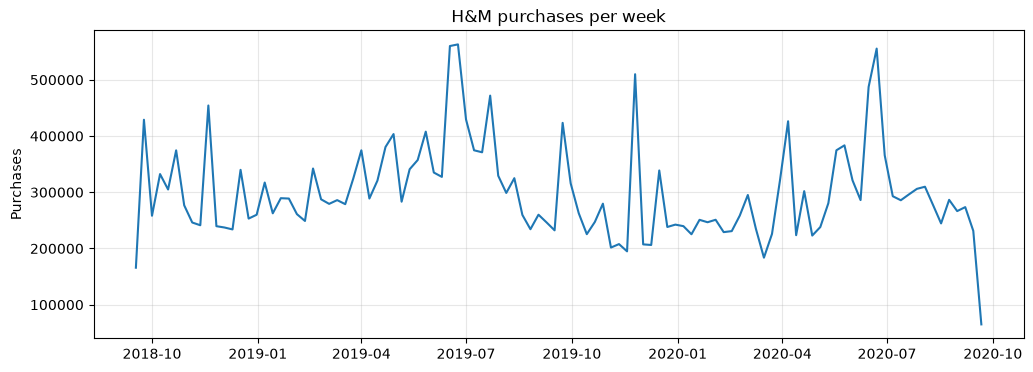

In [5]:
import matplotlib.pyplot as plt

weekly = (
    tx.group_by(pl.col("t_dat").dt.truncate("1w"))
      .len()
      .sort("t_dat")
)

plt.figure(figsize=(12, 4))
plt.plot(weekly["t_dat"], weekly["len"])
plt.title("H&M purchases per week")
plt.ylabel("Purchases")
plt.grid(alpha=0.3)
plt.savefig("../reports/figures/weekly_purchases.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
from pathlib import Path
import time

PROCESSED = Path("../data/processed")
tx.write_parquet(PROCESSED / "transactions.parquet")

t0 = time.time()
tx_check = pl.read_parquet(PROCESSED / "transactions.parquet")
print(f"Reloaded {tx_check.height:,} rows in {time.time() - t0:.1f} s")
print(tx_check.schema)

Reloaded 31,788,324 rows in 2.3 s
Schema([('t_dat', Date), ('customer_id', String), ('article_id', String), ('price', Float64), ('sales_channel_id', Int64)])
